# SBSI tutorial with the V3.9-like model

This notebook repeats the [V3 tutorial](sbsi_api_tutorial.ipynb) with the current **V3.9-like** model:
one measurement flow, one usable-detection classifier, and a blending emulator that acts on each flow draw.

Two things differ from V3:

- **Blending is per draw, not an added constant.** The emulator predicts, for every simulated measurement,
  how far the neighbours push its shape along the applied shear; the shape is then moved by that amount
  (a Möbius shift, which keeps |e| < 1). So the flow and blending parts are computed from the same draws.
- **Detection means "usable".** The classifier gives the probability that a galaxy is detected *and* has a
  finite, usable shape, size and flux measurement.

The model files are not bundled with the repository: set `SBSI_CACHE_DIR` (flow, classifier) and
`BLENDEMU_RUNS_DIR` (blending emulator) to the model store. A GPU makes the response step take about a minute;
on a CPU it takes much longer.

## 1. Setup and catalogue

In [1]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

import sbsi
from sbsi import DiskResponsePredictor, example_path, get_model, load_catalogue, prepare_disk_inputs

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("SBSI:  ", sbsi.__file__)
print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

input_catalogue = load_catalogue(example_path("data", "example_catalog.feather")).reset_index(drop=True)
input_catalogue.head()

SBSI:   /home/z/Zekang.Zhang/SBSI/.claude/worktrees/master-merge/sbsi/__init__.py
device: cuda Quadro P5000


,index,cata_idx,RA,DEC,g1,g2,position_angle,redshift,Re,axis_ratio,sersic_n,r
0,0,773630,180.185728,0.222420,0.0,0.0,164.396647,1.102414,0.162907,0.697792,0.845730,25.733576
1,1,277869,180.118990,0.236218,0.0,0.0,168.168753,0.642087,0.146840,0.341948,0.513552,24.451671
2,2,28030,180.493363,-0.059868,0.0,0.0,91.671930,0.265863,0.396980,0.409923,1.581997,26.839913
3,3,1066306,180.298198,-0.032319,0.0,0.0,152.511604,1.570225,0.155919,0.489980,1.164548,26.660423
4,4,1241052,180.201385,-0.111354,0.0,0.0,41.145542,1.886374,0.192961,0.262081,0.580749,25.564444


## 2. Load the three model parts

`validate()` checks every file against the SHA-256 hash pinned in `configs/models_v3_9_like.json`.

In [2]:
models = get_model("V3.9-like")
models.validate()
predictor = DiskResponsePredictor(models, device=DEVICE, nthread=4)

OBSERVING_CONDITIONS = {"pixel_size": 0.2, "zero_point": 30.0, "psf_fwhm": 0.73,
                        "moffat_beta": 2.224, "pixel_rms": 0.312}
print("flow and classifier inputs:", predictor.flow.condition_preprocessor.feature_names)

[18:43:03] WARNING: /home/conda/feedstock_root/build_artifacts/xgboost-split_1693021084223/work/src/learner.cc:767: 
Parameters: { "device" } are not used.

flow and classifier inputs: ['e1_input_p', 'e2_input_p', 'sersic_n_input_p', 'r_input_p', 'circularized_Re_input_p', 'nbr_close_050', 'nbr_close_100', 'nbr_close_200']


## 3. Build the inputs

The flow and the classifier take the same eight truth-level inputs per galaxy:

- intrinsic shape `e1`, `e2` from the axis ratio and position angle;
- Sérsic index, magnitude `r`, and the circularized half-light radius `Re·sqrt(q)` in arcsec;
- three crowding numbers `nbr_close_050/100/200`: the summed flux of all neighbours relative to the galaxy,
  weighted by a Gaussian in separation of width 0.5, 1 and 2 arcsec (log1p of the sum).

The blending emulator instead uses a table of galaxy–neighbour pairs (up to 19 neighbours within 10 arcsec),
scaled by the PSF size and noise level. Every catalogue galaxy is a primary here: V3.9's emulator applies no
pair cuts, and a galaxy with no neighbour simply gets zero blending response.

`prepare_disk_inputs` builds both; the inputs are indexed by the catalogue `index`.

In [3]:
inputs, pairs = prepare_disk_inputs(input_catalogue, OBSERVING_CONDITIONS, workers=4)
print(f"{len(inputs)} galaxies, {len(pairs)} neighbour pairs ({len(pairs)/len(inputs):.1f} per galaxy)")
inputs.describe().T

111210 galaxies, 1191064 neighbour pairs (10.7 per galaxy)


,count,mean,std,min,25%,50%,75%,max
e1_input_p,111210.0,0.000029,0.284029,-0.821749,-2.068298e-01,0.000607,0.205360,0.811181
e2_input_p,111210.0,0.000110,0.284824,-0.840306,-2.055600e-01,0.000813,0.206396,0.838064
sersic_n_input_p,111210.0,1.313921,0.647126,0.500009,8.968459e-01,1.168654,1.548409,5.999692
r_input_p,111210.0,24.806163,1.742505,12.688146,2.380368e+01,25.225624,26.191089,26.999998
circularized_Re_input_p,111210.0,0.212257,0.167576,0.022216,1.290923e-01,0.173630,0.242314,4.096458
nbr_close_050,111210.0,0.108033,0.441677,0.000000,5.896813e-12,0.000002,0.004318,11.256227
nbr_close_100,111210.0,0.404349,0.824034,0.000000,1.366093e-03,0.038989,0.377983,12.423104
nbr_close_200,111210.0,1.243325,1.282076,0.000000,2.158760e-01,0.826045,1.900497,12.714903


## 4. Predict the response

The response is measured the same way as on simulations: shear every input shape by $+h$ and by $-h$
($h = 0.02$ along $g_1$), draw measurements at both, and take

$$R = \frac{\langle e_1\rangle_{+} - \langle e_1\rangle_{-}}{2h}.$$

Both legs use the **same random draws** (common random numbers), and draws come in mirrored pairs $z, -z$,
which removes most of the sampling noise from the difference. For each draw the blending emulator predicts a
response from the galaxy's neighbours and that draw's measured size and flux; the shape is then shifted by
that response times the applied shear. Splitting each mean into the unshifted shape and the shift gives

$$R_{\mathrm{model}} = R_{\mathrm{flow}} + R_{\mathrm{blend}}$$

exactly, from the same draws.

The measurement cut is applied to each draw: FLUX_RADIUS > 0.6 arcsec and MAG_AUTO < 25.8 (`main`), as in the
published V3.9 bias (`r075` is the stricter FLUX_RADIUS ≥ 0.75 arcsec). `predict` stores, per galaxy and leg,
the fraction of draws passing each cut and the mean kept shape and blending shift. With 64 draws per galaxy
it takes about a minute on a GPU.

In [4]:
prediction = predictor.predict(inputs, pairs, shear=0.02, n_draws=64, random_seed=7301)

### Population response, with and without cut and detection weight

The catalogue response is a ratio of sums over galaxies, separately in each leg (as for a simulation):
$R = (N_+/D_+ - N_-/D_-)/2h$ with $N = \sum_i w_i\,\overline{e_1}_i$ and $D = \sum_i w_i\,\text{(fraction passing)}_i$.
The weight $w_i$ is 1, or the classifier's usable probability in that leg. Uncertainties (`_err`) are 1σ from
bootstrapping galaxies (500 resamples); they include the draw noise. `prediction.response(cut, weight)` gives
a single setting.

In [5]:
prediction.summary().round(4)

,R_flow,R_flow_err,R_blend,R_blend_err,R_model,R_model_err
uncut,0.1272,0.0019,0.2406,0.0019,0.3677,0.0026
main cut,0.2707,0.0029,0.2869,0.0023,0.5576,0.0035
main cut x usable probability,0.3571,0.0038,0.2016,0.0017,0.5586,0.0040


### Distribution of the two response channels

Per galaxy and without the cut, $R_{\mathrm{flow},i} = (\overline{e_1}_{+} - \overline{e_1}_{-})/2h$ over its 64
paired draws, and likewise for the blending shift. With only 64 draws each galaxy's value is noisy; the
catalogue means above are what matter.

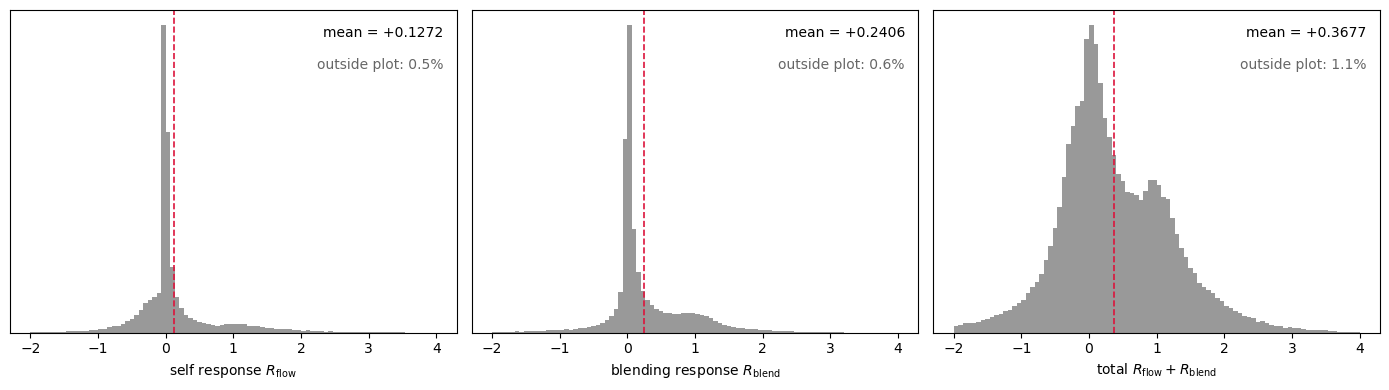

galaxies with no neighbour within 10 arcsec: 0.00%


In [6]:
per_galaxy = prediction.per_galaxy()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
channels = (("R_flow", r"self response $R_{\mathrm{flow}}$"),
            ("R_blend", r"blending response $R_{\mathrm{blend}}$"),
            ("R_total", r"total $R_{\mathrm{flow}} + R_{\mathrm{blend}}$"))
span = (-2, 4)
for ax, (column, label) in zip(axes, channels):
    values = per_galaxy[column]
    ax.hist(values, bins=90, range=span, color="0.6")
    ax.text(0.97, 0.85, f"outside plot: {np.mean((values < span[0]) | (values > span[1])):.1%}",
            transform=ax.transAxes, ha="right", va="top", color="0.4")
    ax.axvline(values.mean(), color="crimson", ls="--", lw=1.2)
    ax.text(0.97, 0.95, f"mean = {values.mean():+.4f}", transform=ax.transAxes, ha="right", va="top")
    ax.set_xlabel(label)
    ax.set_yticks([])
fig.tight_layout()
plt.show()
print(f"galaxies with no neighbour within 10 arcsec: {np.mean(~inputs.index.isin(pairs['index_input_p'])):.2%}")

### The flow's direct output: measured-parameter distributions

The flow models the joint distribution of four measured quantities -- shape ($g_1$, $g_2$), FLUX_RADIUS and
flux -- for each galaxy's inputs. Below are 4096 draws for three galaxies picked near the magnitudes of the
README figure (bright, typical, faint), chosen to be resolved and nearly isolated, at zero shear and before the blending shift. The cross marks the input
shape and magnitude and the PSF-convolved input radius.

flow outputs: ('measured_ngmix_g1', 'measured_ngmix_g2', 'measured_flux_radius', 'measured_flux_from_mag_auto')


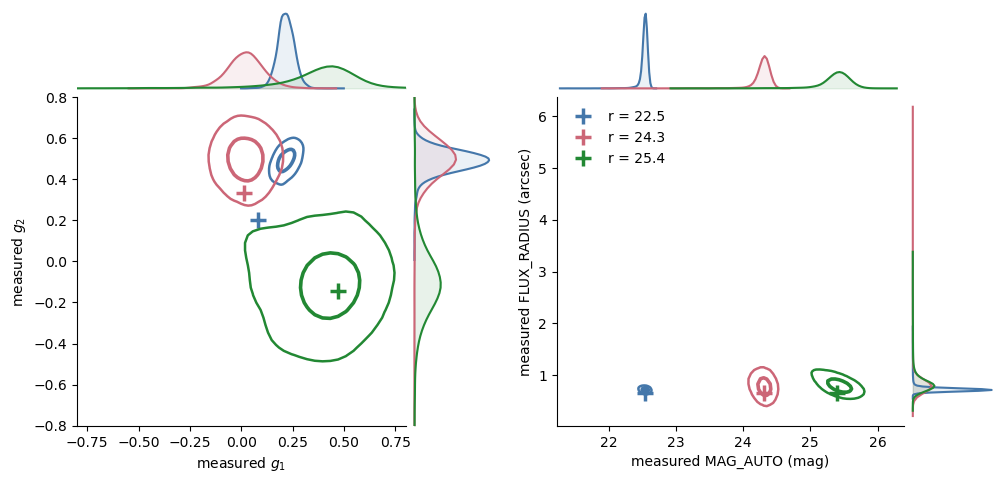

In [7]:
from scipy.ndimage import gaussian_filter, gaussian_filter1d
from mpl_toolkits.axes_grid1 import make_axes_locatable

MASS_LEVELS = (0.393, 0.865)   # 1σ, 2σ in 2D
SMOOTHING, COLORS = 1.6, ("#4477AA", "#CC6677", "#228833")
PAD = int(np.ceil(4*SMOOTHING))


def pad_edges(edges):
    return edges[0] + (edges[1] - edges[0])*np.arange(-PAD, len(edges) + PAD)


def density_contours(ax, x, y, color, bins=50):
    H2, xe, ye = np.histogram2d(x, y, bins=bins)
    H2 = gaussian_filter(np.pad(H2.T, PAD), SMOOTHING)
    xe, ye = pad_edges(xe), pad_edges(ye)
    ranked = np.sort(H2.ravel())[::-1]
    cdf = np.cumsum(ranked)/ranked.sum()
    levels = sorted({ranked[np.searchsorted(cdf, m)] for m in MASS_LEVELS})
    ax.contour((xe[:-1] + xe[1:])/2, (ye[:-1] + ye[1:])/2, H2, levels=levels, colors=color,
               linewidths=np.linspace(1.8, 2.6, len(levels)))


def marginal(ax, x, color, vertical=False, bins=70):
    h, edges = np.histogram(x, bins=bins)
    h = gaussian_filter1d(np.pad(h.astype(float), PAD), SMOOTHING)
    edges = pad_edges(edges)
    centre = (edges[:-1] + edges[1:])/2
    h /= np.trapz(h, centre)
    if vertical:
        ax.plot(h, centre, color=color, lw=1.5)
        ax.fill_betweenx(centre, h, color=color, alpha=0.1)
    else:
        ax.plot(centre, h, color=color, lw=1.5)
        ax.fill_between(centre, h, color=color, alpha=0.1)


def joint_axes(fig, spec):
    joint = fig.add_subplot(spec)
    divider = make_axes_locatable(joint)
    top = divider.append_axes("top", size="25%", pad=0.05, sharex=joint)
    right = divider.append_axes("right", size="25%", pad=0.05, sharey=joint)
    top.axis("off"), right.axis("off")
    return joint, top, right


# Resolved (circularized radius near 0.4 arcsec), moderately elliptical, nearly isolated galaxies.
e_abs = np.hypot(inputs["e1_input_p"], inputs["e2_input_p"]).to_numpy()
radius_in = inputs["circularized_Re_input_p"].to_numpy()
eligible = (e_abs > 0.2) & (e_abs < 0.5) & (inputs["nbr_close_100"].to_numpy() < 0.05)
picks = [int(np.flatnonzero(eligible & (np.abs(inputs["r_input_p"].to_numpy() - r) < 0.1))[
             np.argmin(np.abs(radius_in[eligible & (np.abs(inputs["r_input_p"].to_numpy() - r) < 0.1)] - 0.4))])
         for r in (22.5, 24.4, 25.4)]
sample = predictor.sample(inputs.iloc[picks], n_samples=4096, random_seed=7301)
print("flow outputs:", sample.target_names)
psf_re = 0.73*np.sqrt((2**(1/1.224) - 1)/(2**(1/2.224) - 1))/2

fig = plt.figure(figsize=(12, 5.4))
grid = fig.add_gridspec(1, 2, wspace=0.12)
shape_axes, phot_axes = joint_axes(fig, grid[0]), joint_axes(fig, grid[1])
for i, (row, color) in enumerate(zip(picks, COLORS)):
    g1, g2 = sample.column("measured_ngmix_g1")[i], sample.column("measured_ngmix_g2")[i]
    radius = sample.column("measured_flux_radius")[i]*OBSERVING_CONDITIONS["pixel_size"]   # pixels -> arcsec
    mag = 30 - 2.5*np.log10(np.clip(sample.column("measured_flux_from_mag_auto")[i], 1e-30, None))
    for (joint, top, right), x, y in ((shape_axes, g1, g2), (phot_axes, mag, radius)):
        density_contours(joint, x, y, color)
        marginal(top, x, color)
        marginal(right, y, color, vertical=True)
    truth = inputs.iloc[row]
    shape_axes[0].plot(truth["e1_input_p"], truth["e2_input_p"], "+", color=color, ms=12, mew=2.5)
    phot_axes[0].plot(truth["r_input_p"], np.hypot(truth["circularized_Re_input_p"], psf_re), "+",
                      color=color, ms=12, mew=2.5, label=f"r = {truth['r_input_p']:.1f}")
shape_axes[0].set(xlabel=r"measured $g_1$", ylabel=r"measured $g_2$", xlim=(-0.8, 0.8), ylim=(-0.8, 0.8),
                  aspect="equal")
phot_axes[0].set(xlabel="measured MAG_AUTO (mag)", ylabel="measured FLUX_RADIUS (arcsec)")
phot_axes[0].legend(loc="upper left", frameon=False)
for ax in (shape_axes[0], phot_axes[0]):
    ax.spines[["top", "right"]].set_visible(False)
plt.show()

### Usable-detection probability per galaxy

The classifier scores each galaxy from the same eight inputs. Weighting the response by it (third row of the
table above) is how the model accounts for which galaxies end up in the measured catalogue.

count    1.112100e+05
mean     7.288355e-01
std      3.705840e-01
min      2.544553e-15
25%      4.673238e-01
50%      9.627403e-01
75%      9.903642e-01
max      9.998350e-01


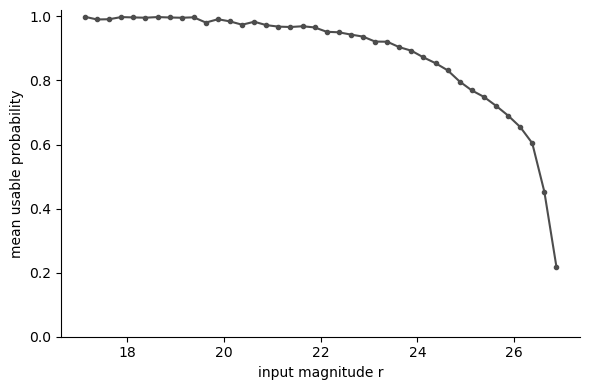

In [8]:
print(per_galaxy["P_usable"].describe().to_string())
fig, ax = plt.subplots(figsize=(6, 4))
bins = np.arange(17, 27.25, 0.25)
magnitude = inputs["r_input_p"].to_numpy()
which = np.digitize(magnitude, bins)
centre = 0.5*(bins[1:] + bins[:-1])
mean_p = [per_galaxy["P_usable"].to_numpy()[which == k].mean() if np.any(which == k) else np.nan
          for k in range(1, len(bins))]
ax.plot(centre, mean_p, "o-", color="0.3", ms=3)
ax.set(xlabel="input magnitude r", ylabel="mean usable probability", ylim=(0, 1.02))
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

### Comparing against a simulation

With a matched simulation response measured under the same cut, the multiplicative bias is

$$m = R_{\mathrm{sim}} / R_{\mathrm{model}} - 1.$$

`prediction.multiplicative_bias(R_sim, cut="main", weight="usable")` returns $m$ and its 1σ error from the
model side (add the simulation's own error). On the development constant-shear simulations V3.9-like gives
m = +0.02% ± 0.27% with the main cut and the usable probability (`configs/models_v3_9_like.json`,
`results.primary`); it has not been independently validated.